In [ ]:

!pip -q install librosa soundfile

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Biblioteki zostały załadowane!")


Biblioteki zostały załadowane!


In [ ]:

uploaded = files.upload()

nagrania = {}

for nazwa in uploaded.keys():
    y, sr = librosa.load(nazwa, sr=22050)
    nagrania[nazwa] = y
    print(f"{nazwa}: {len(y)/sr:.2f} s")

print("Wszystkie nagrania zostały wczytane!")


Saving Open_central_unrounded_vowel.ogg to Open_central_unrounded_vowel.ogg
Saving Audio_Sample_-_The_Quick_Brown_Fox_Jumps_Over_The_Lazy_Dog.ogg to Audio_Sample_-_The_Quick_Brown_Fox_Jumps_Over_The_Lazy_Dog.ogg
Saving En-us-hello.wav to En-us-hello (1).wav
Open_central_unrounded_vowel.ogg: 1.07 s
Audio_Sample_-_The_Quick_Brown_Fox_Jumps_Over_The_Lazy_Dog.ogg: 3.81 s
En-us-hello (1).wav: 0.49 s
Wszystkie nagrania zostały wczytane!


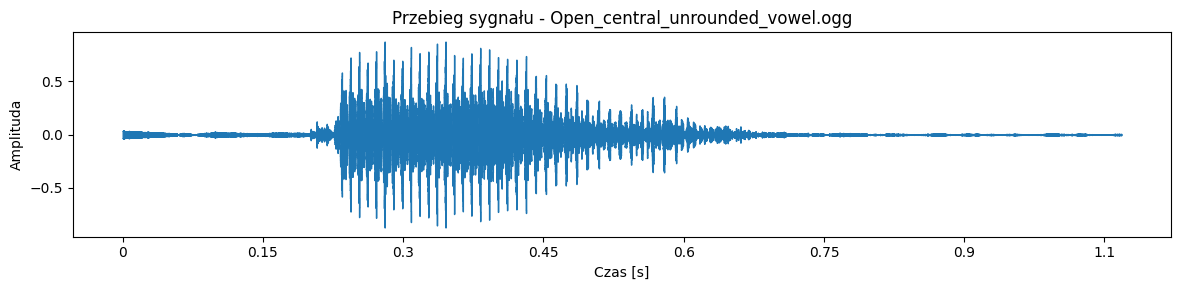

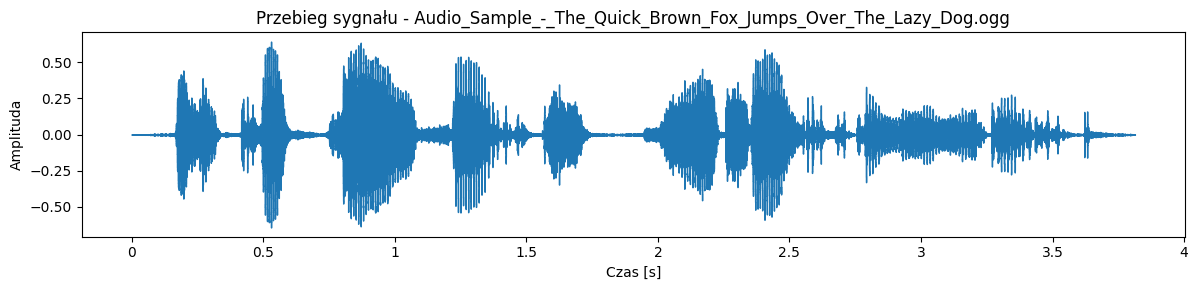

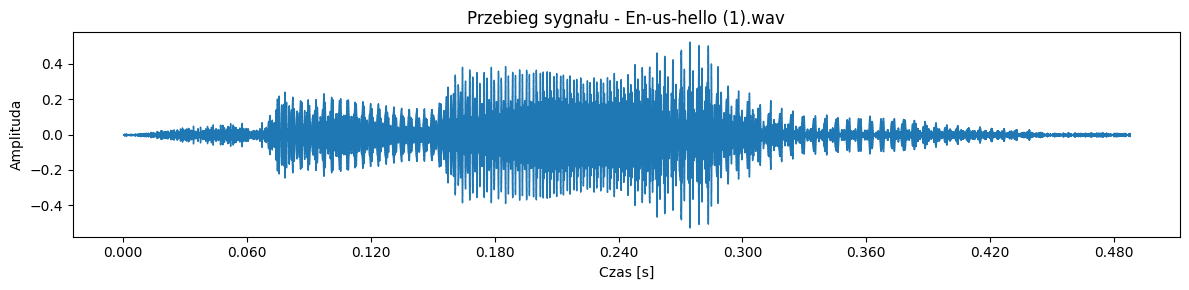

In [ ]:

for nazwa, y in nagrania.items():
    plt.figure(figsize=(12, 3))
    librosa.display.waveshow(y, sr=22050)
    plt.title(f"Przebieg sygnału - {nazwa}")
    plt.xlabel("Czas [s]")
    plt.ylabel("Amplituda")
    plt.tight_layout()
    plt.show()


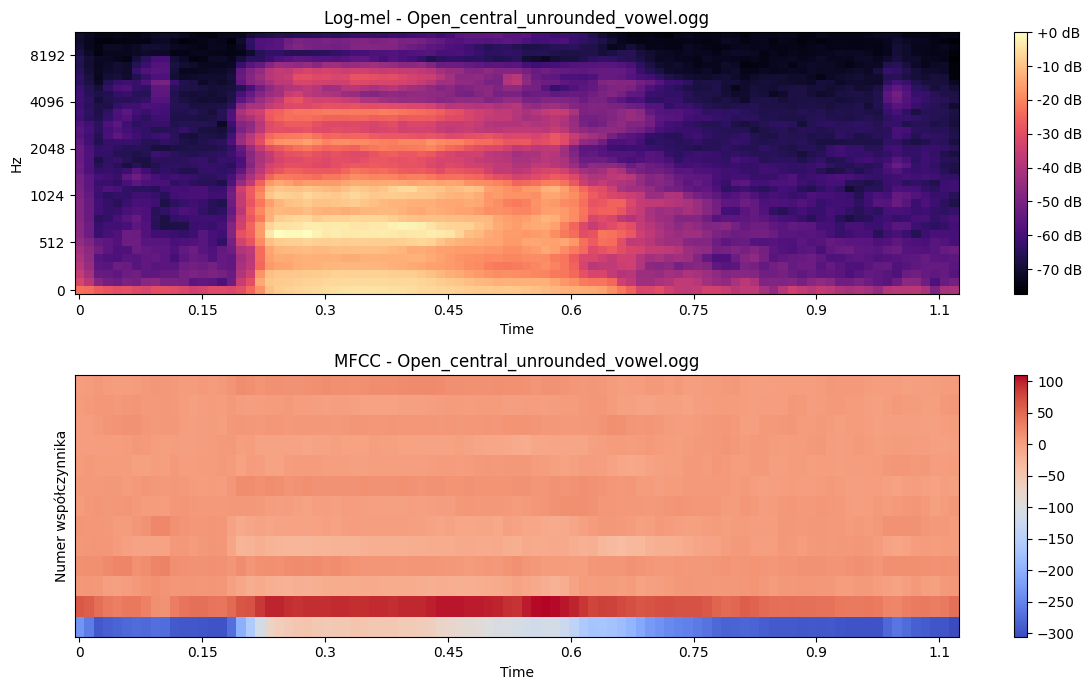

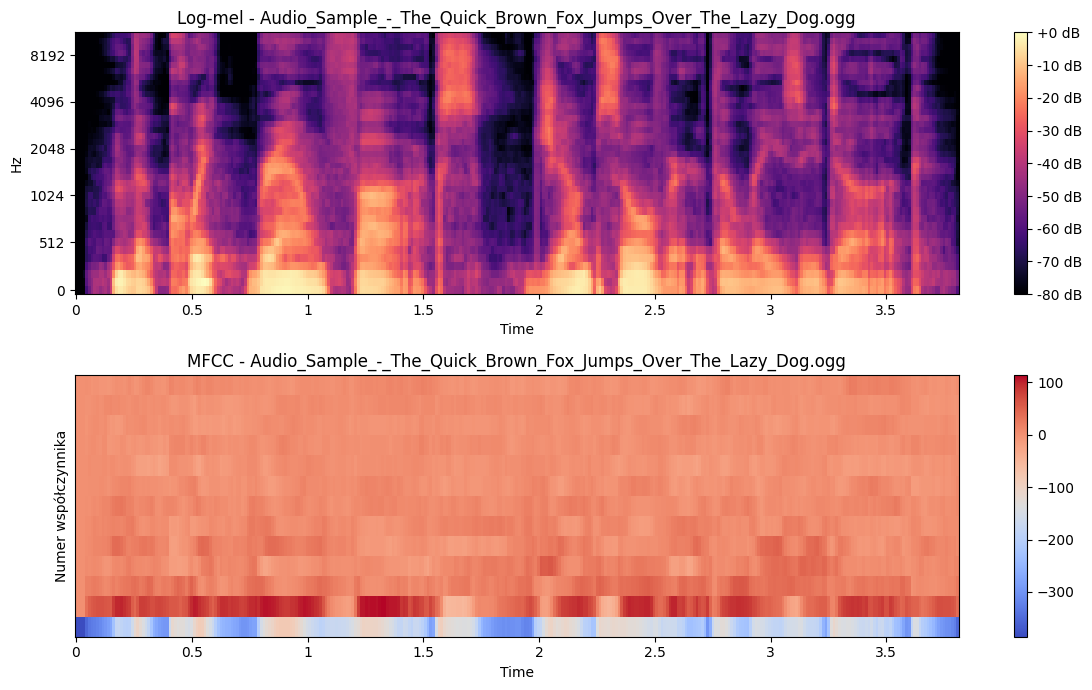

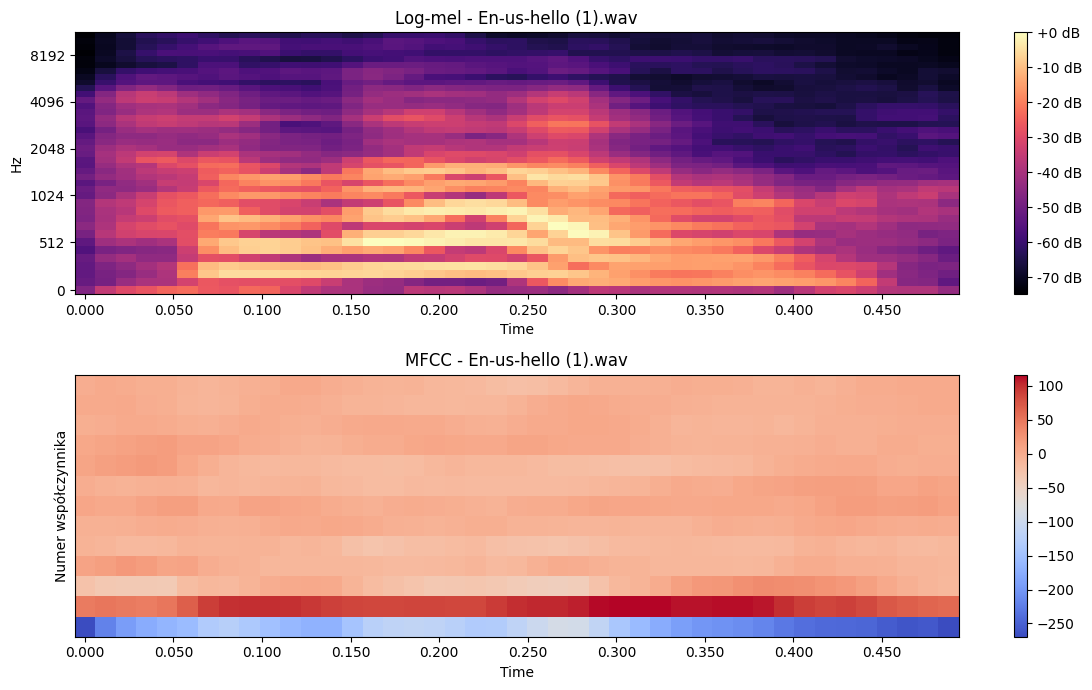

In [ ]:

for nazwa, y in nagrania.items():
    mel = librosa.feature.melspectrogram(
        y=y, sr=22050, n_fft=1024,
        hop_length=256, n_mels=40
    )

    log_mel = librosa.power_to_db(mel, ref=np.max)

    mfcc = librosa.feature.mfcc(
        y=y, sr=22050, n_mfcc=13,
        n_fft=1024, hop_length=256,
        n_mels=40
    )

    fig, ax = plt.subplots(2, 1, figsize=(12, 7))

    img1 = librosa.display.specshow(
        log_mel, sr=22050, hop_length=256,
        x_axis="time", y_axis="mel", ax=ax[0]
    )
    ax[0].set_title(f"Log-mel - {nazwa}")
    fig.colorbar(img1, ax=ax[0], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        mfcc, sr=22050, hop_length=256,
        x_axis="time", ax=ax[1]
    )
    ax[1].set_title(f"MFCC - {nazwa}")
    ax[1].set_ylabel("Numer współczynnika")
    fig.colorbar(img2, ax=ax[1])

    plt.tight_layout()
    plt.show()


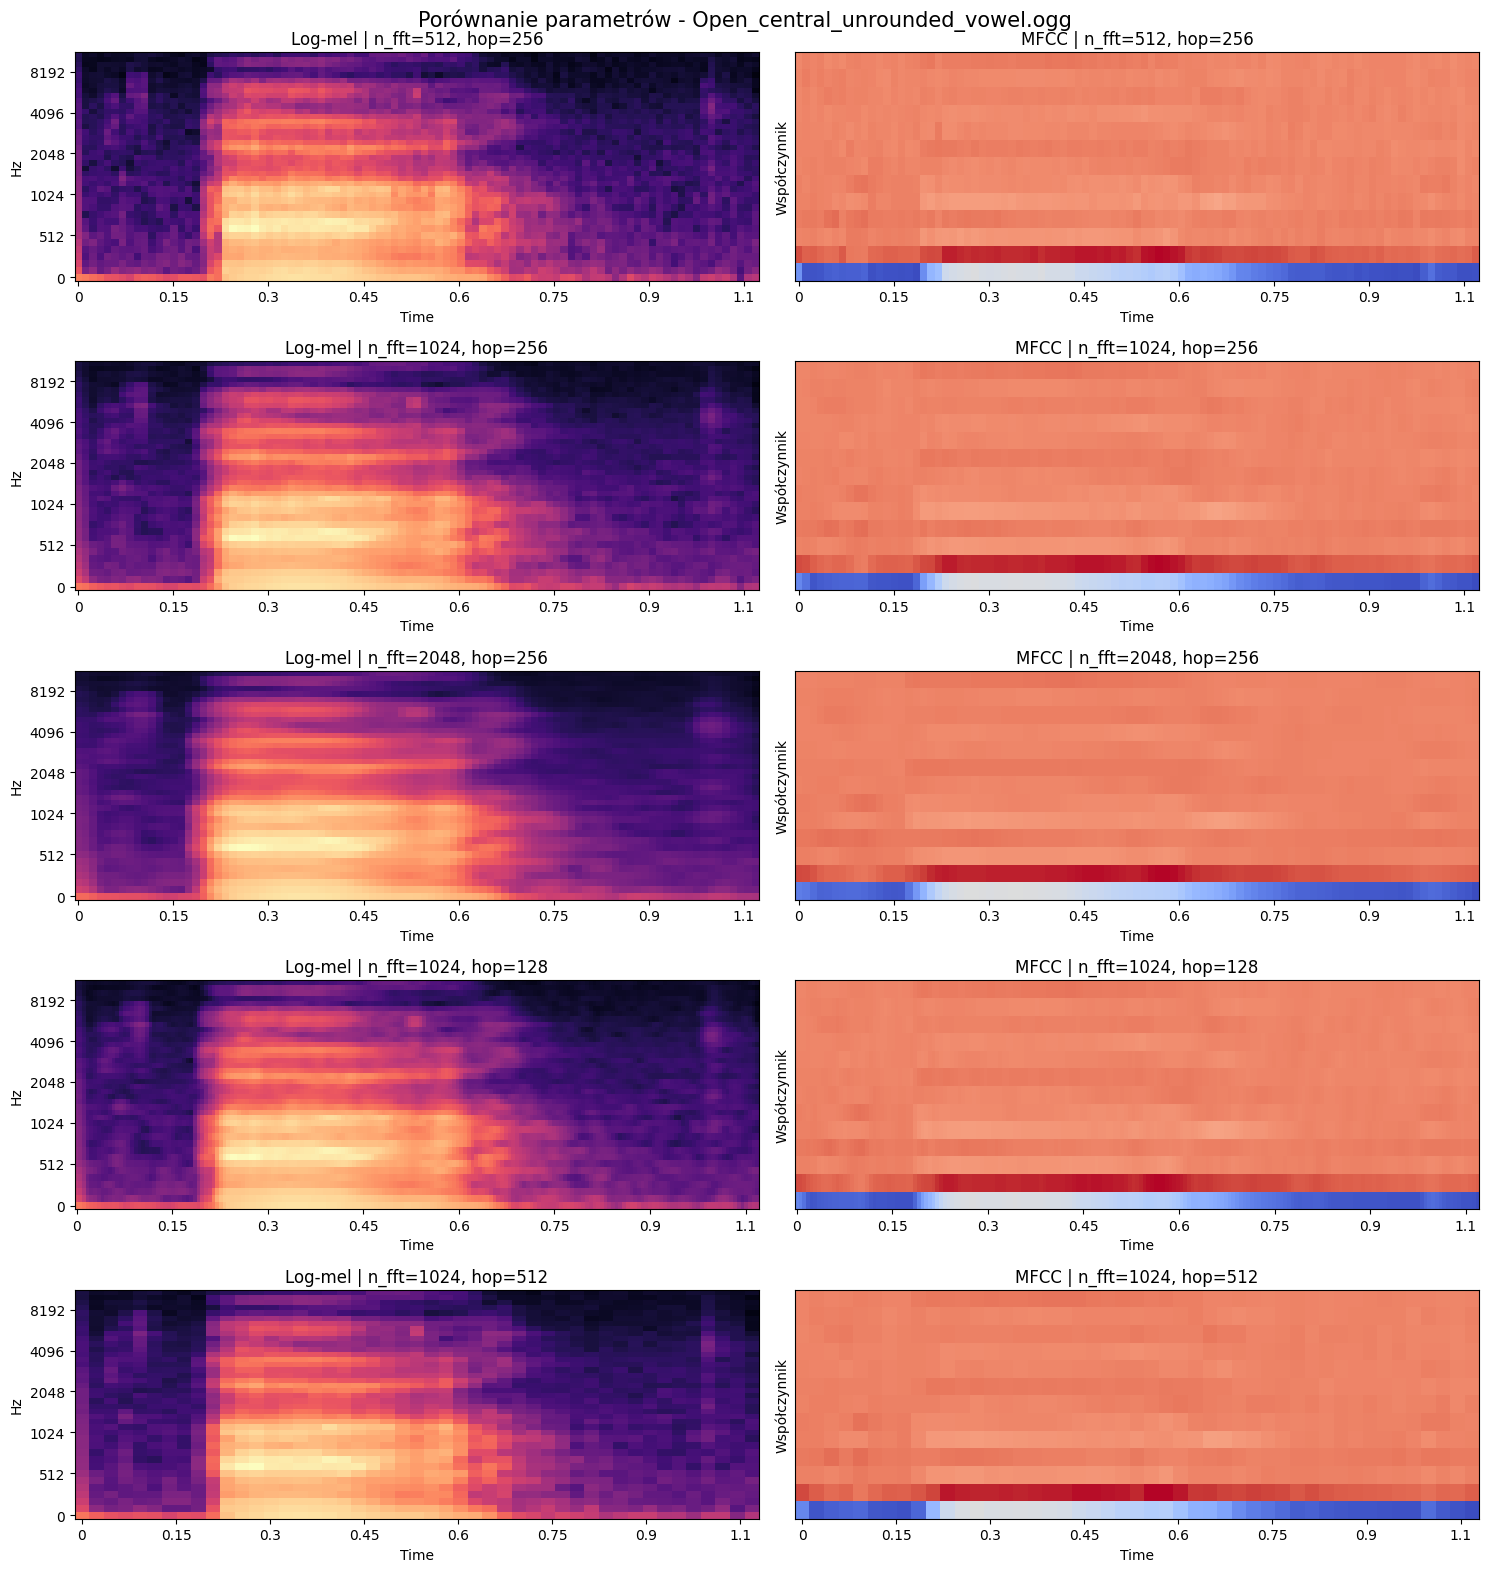

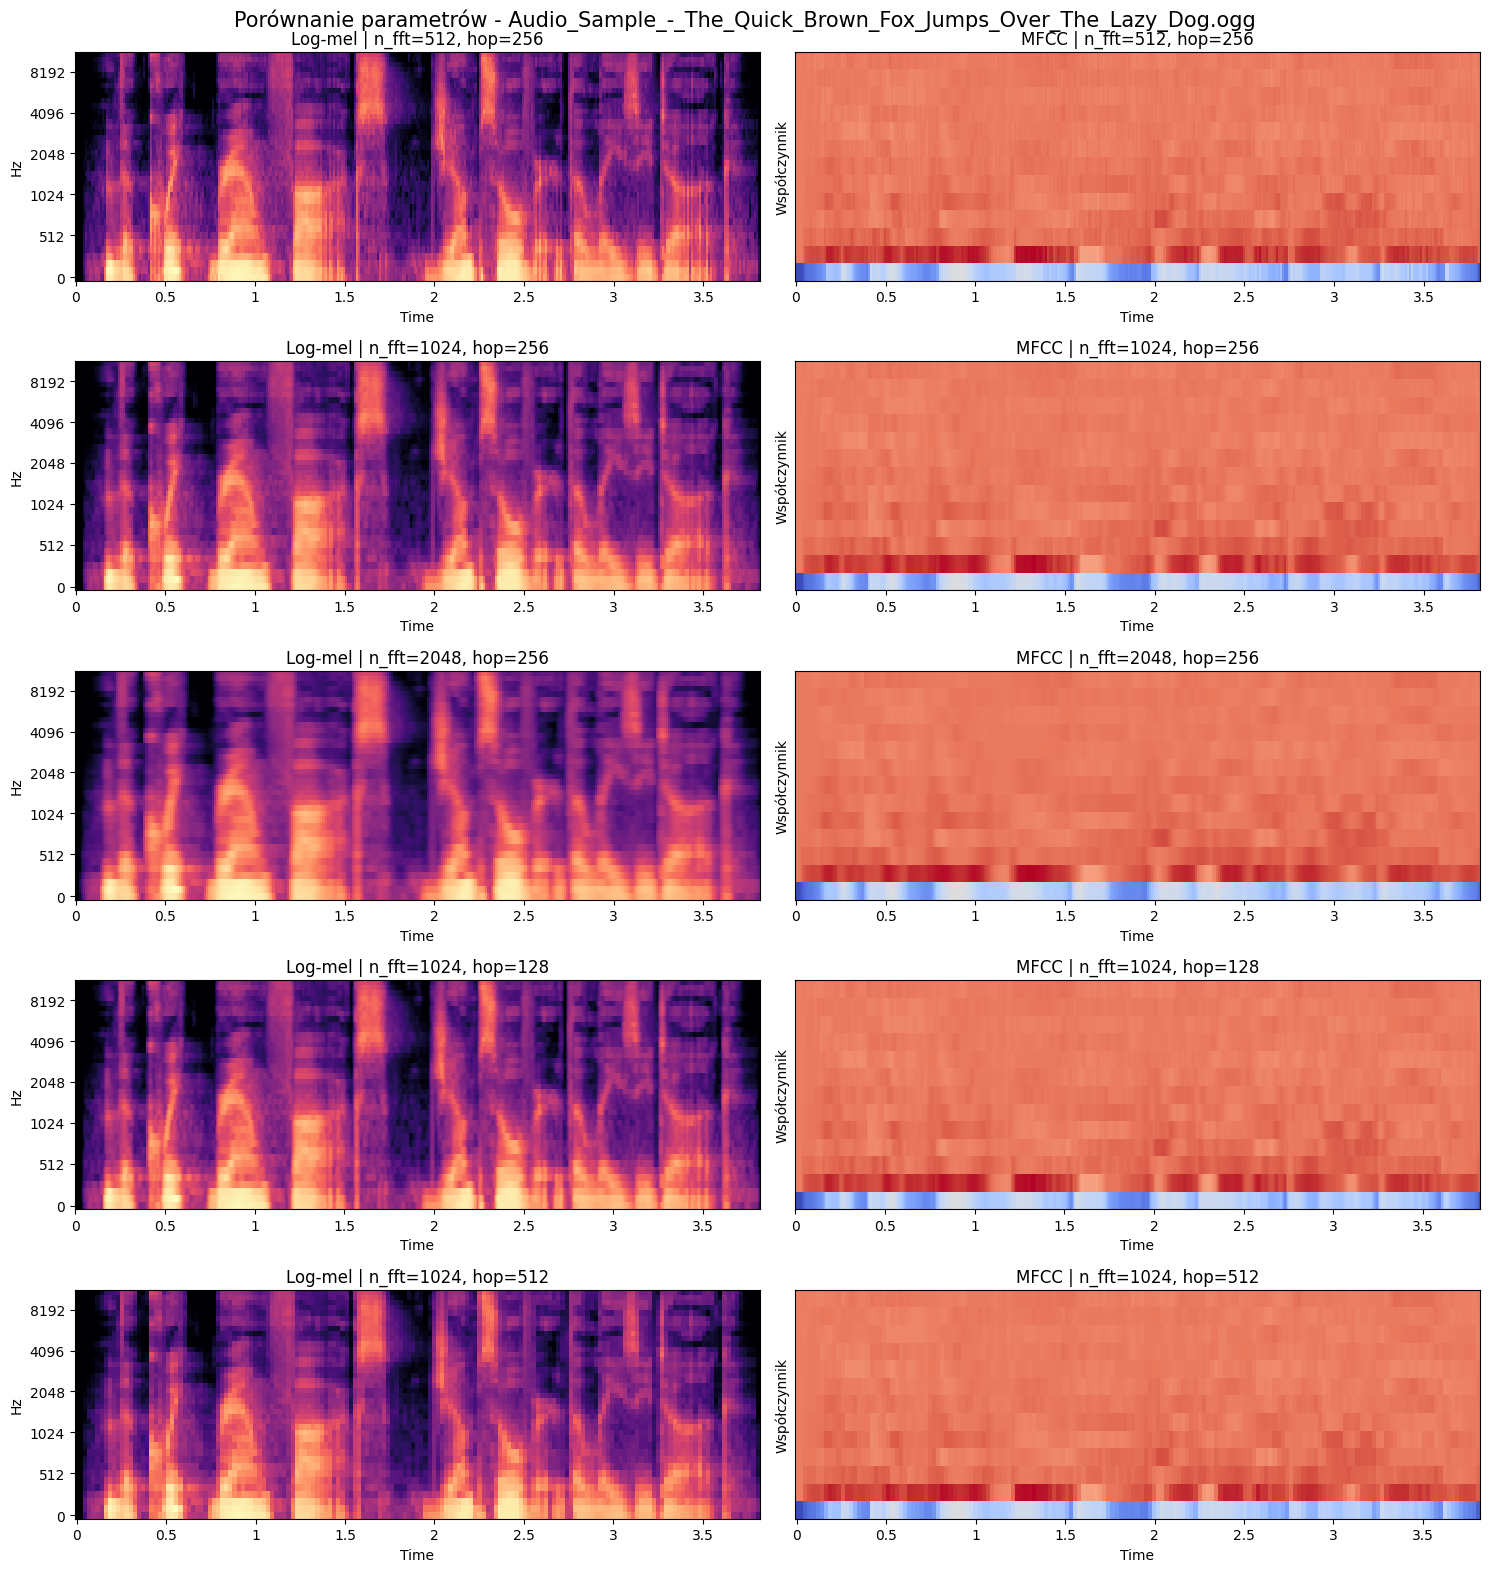

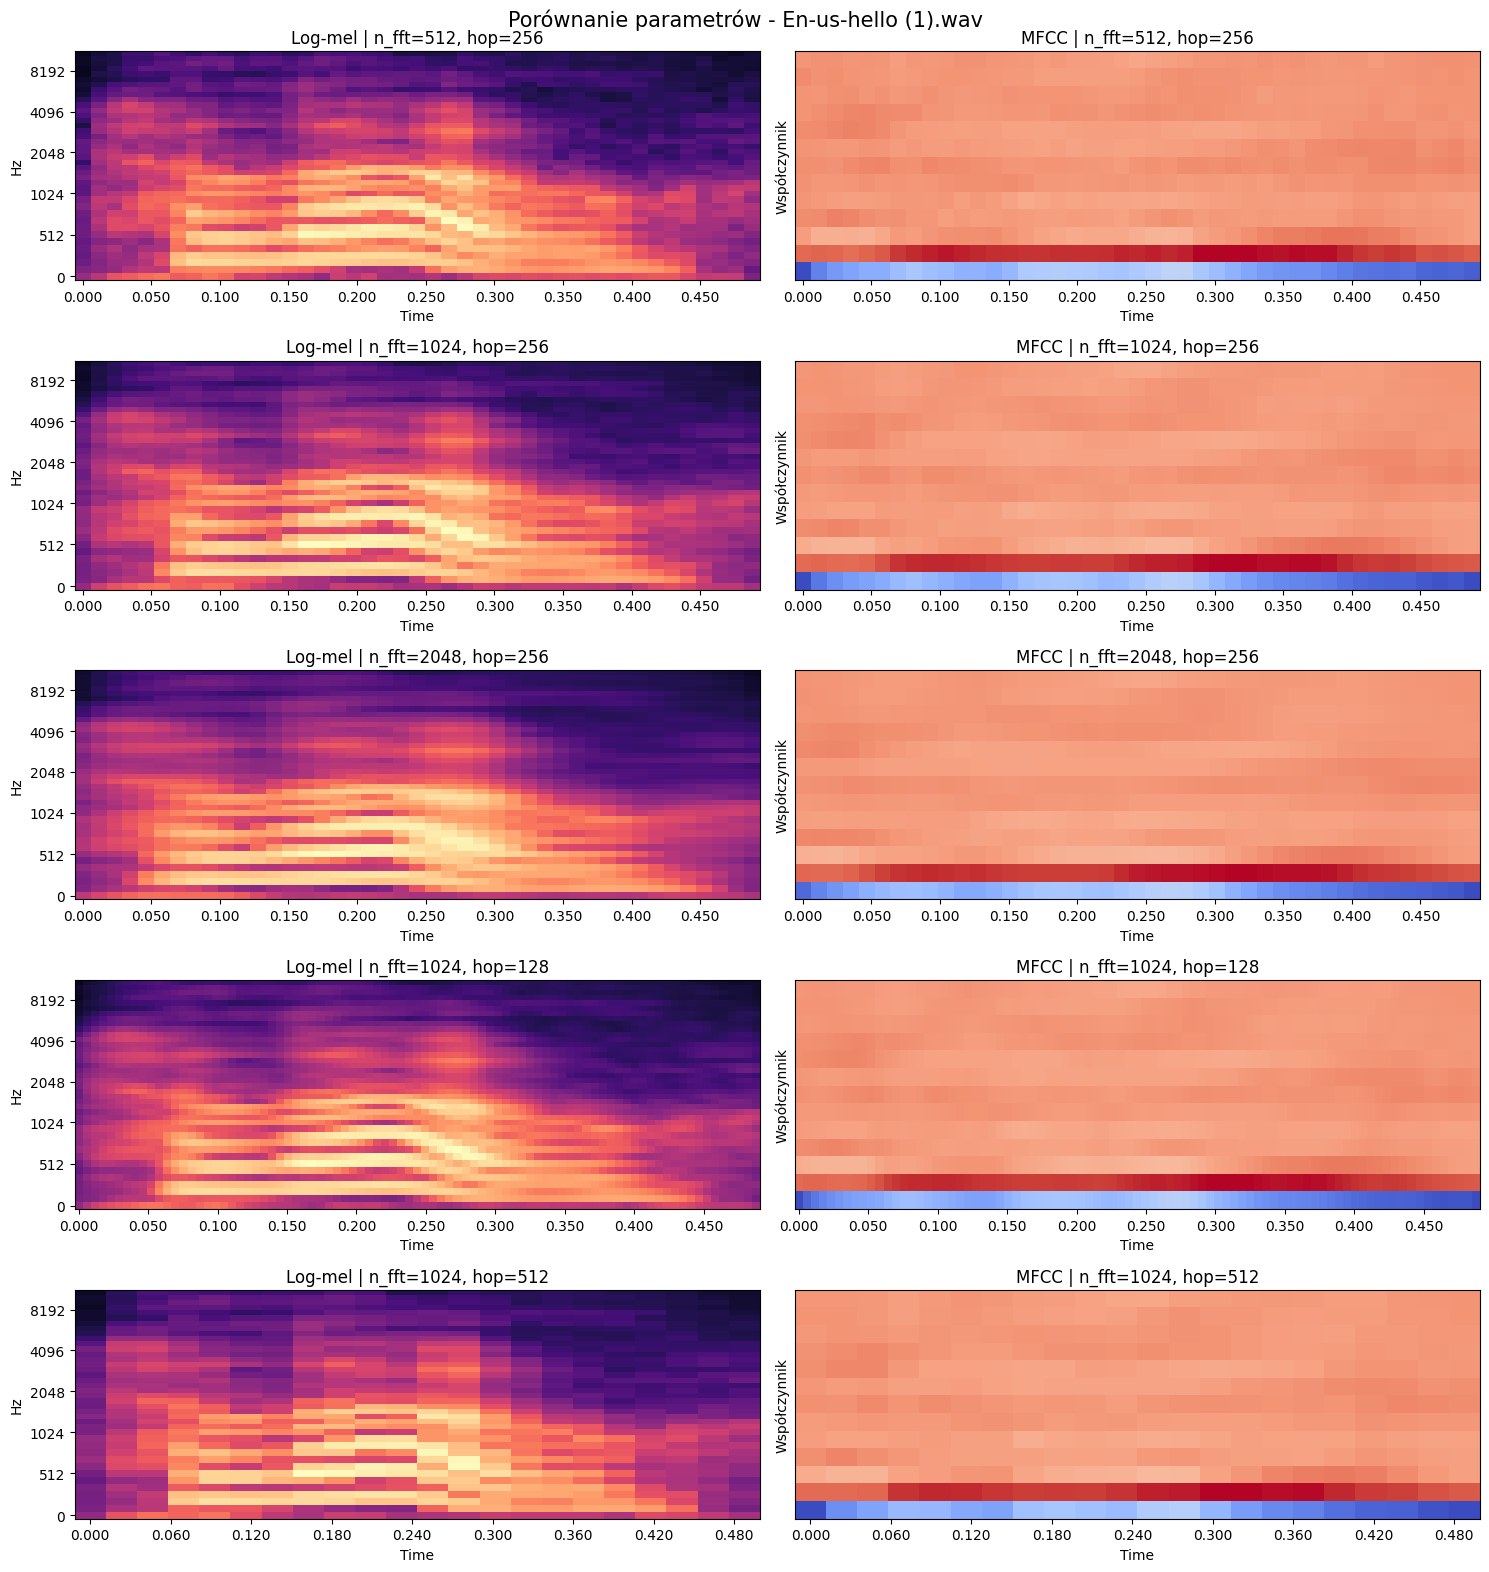

In [ ]:

parametry = [
    (512, 256),
    (1024, 256),
    (2048, 256),
    (1024, 128),
    (1024, 512)
]

for nazwa, y in nagrania.items():
    fig, ax = plt.subplots(
        len(parametry), 2, figsize=(15, 16)
    )

    for i, (n_fft, hop_length) in enumerate(parametry):
        mel = librosa.feature.melspectrogram(
            y=y, sr=22050, n_fft=n_fft,
            hop_length=hop_length, n_mels=40
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        mfcc = librosa.feature.mfcc(
            S=log_mel, n_mfcc=13
        )

        librosa.display.specshow(
            log_mel, sr=22050, hop_length=hop_length,
            x_axis="time", y_axis="mel", ax=ax[i, 0],
            vmin=-80, vmax=0
        )

        ax[i, 0].set_title(
            f"Log-mel | n_fft={n_fft}, hop={hop_length}"
        )

        librosa.display.specshow(
            mfcc, sr=22050, hop_length=hop_length,
            x_axis="time", ax=ax[i, 1]
        )

        ax[i, 1].set_title(
            f"MFCC | n_fft={n_fft}, hop={hop_length}"
        )
        ax[i, 1].set_ylabel("Współczynnik")

    fig.suptitle(f"Porównanie parametrów - {nazwa}", fontsize=15)
    plt.tight_layout()
    plt.show()
